# How Reliable Is Wikidata for Identifying Olympic Athletes?

### An exploratory analysis of biographical matching and data quality

## 1. Introduction

In this project, I investigate whether participating in elite sports affects life expectancy by comparing the lifespans of Olympic athletes with those of the general population. I combine data from several sources to obtain Olympic participation records and biographical information.

In order to study athletes' lifespans, Olympic participation records must first be linked to the correct biographical entries. This, however, presents several challenges: multiple individuals may share similar names, historical records may be incomplete, and search results do not necessarily identify the intended athlete.

The initial data collection process searches Wikidata using athletes' names and selects the first returned result, even when multiple possible matches are found. Before relying on these matches for lifespan analysis, it is important to investigate their reliability.

This report explores three questions:

1. How frequently do Wikidata searches return multiple possible matches, and how is this related to suspicious biographical information?
2. How does the availability of birthdates and deathdates vary across Olympic generations?
3. Are chronological inconsistencies more common among athletes from certain historical periods?

The findings will help identify possible improvements to the matching algorithm and limitations that must be considered in the subsequent lifespan analysis.

**Scope:** This preliminary analysis uses the first 21 completed scraping batches, containing 5,693 unique athletes. The results should not yet be generalized to all Olympic athletes.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Use only the first 21 completed batches
files = [Path(f"../data/entries{i}of500.csv") for i in range(1, 22)]

# Verify that all files exist
missing_files = [file for file in files if not file.exists()]

if missing_files:
    raise FileNotFoundError(f"Missing batches: {missing_files}")

# Create one dataframe with all entries
df = pd.concat([pd.read_csv(file) for file in files], ignore_index=True)

athletes_df = df.drop_duplicates(subset="ID").copy()

print(f"Loaded {len(files)} batches")
print(f"Unique athletes: {len(athletes_df):,}")
print(f"Olympic participation records: {len(df):,}")

Loaded 21 batches
Unique athletes: 5,693
Olympic participation records: 10,395


## 2. Data and Methodology

### Data sources

I use the Kaggle dataset [*120 years of Olympic history: athletes and results*](https://www.kaggle.com/datasets/heesoo37/120-years-of-olympic-history-athletes-and-results) for Olympic participation records and [Wikidata](https://www.wikidata.org/) for biographical information. Biographical information from [Olympedia](https://www.olympedia.org/), an online database of Olympic athletes and results, is used to help verify potential matches between the datasets.

The resulting dataset contains Olympic participation information, Wikidata identifiers, birthdates, deathdates, and diagnostic messages generated during scraping.

### Matching procedure

The initial scraper uses athlete information cross-referenced with Olympedia to search Wikidata using athlete names and possible name variations. It selects the first returned candidate as the presumed match.

This procedure is straightforward but potentially unreliable when several individuals share similar names.

### Quality assessment

To identify potentially incorrect matches, the analysis applies several chronological checks:

- Birth year later than the year of Olympic participation.
- Death year earlier than the year of Olympic participation.
- Age at Olympic participation below 10 years.
- Age at Olympic participation above 80 years.

An athlete is flagged as suspicious if any of these conditions occurs for at least one participation record. The age thresholds are used as indicators of potentially implausible matches rather than strict criteria for determining whether a record is incorrect.

These checks identify chronological inconsistencies, not confirmed identity errors. An incorrect match may still appear chronologically plausible. Missing birthdates or deathdates may also prevent certain inconsistencies from being detected.

### 3.1 Wikidata Search Ambiguity

#### Findings

A strong association was observed between the number of Wikidata search results and the percentage of athletes with chronologically inconsistent biographical information.

Among athletes whose names returned only one Wikidata search result, just 0.9% were flagged. This percentage increased substantially when multiple results were returned, reaching 14.2% for two results, 20.5% for three to five results, and 38.2% for 21 to 50 results.

Overall, 22.5% of athletes with two to 50 search results were flagged, compared with only 0.9% of athletes with a single result.

These findings suggest that the number of search results may be a useful indicator of potential identification problems. When multiple Wikidata entries are returned for a name, selecting the first result may be more likely to produce an incorrect match.

However, the number of search results does not necessarily correspond to the number of plausible matches. Some results may refer to unrelated individuals, and even a single search result does not guarantee that the correct person has been identified.

Furthermore, chronological inconsistencies only identify a subset of potential matching errors. An incorrect match may still produce plausible birthdates and deathdates.

The results therefore suggest an association between search ambiguity and detectable chronological inconsistencies, rather than providing a direct measure of matching accuracy.

In [34]:
# Create a working copy of all participation records
quality_df = df.copy()

# Extract birth and death years
quality_df["birth_year"] = pd.to_numeric(quality_df["birthdate"].str.extract(r"^(\d{4})")[0], errors="coerce")

quality_df["death_year"] = pd.to_numeric(quality_df["deathdate"].str.extract(r"^(\d{4})")[0], errors="coerce")

# Calculate age at Olympic participation
quality_df["age_at_olympics"] = (quality_df["Year"] - quality_df["birth_year"])

# Identify individual chronological inconsistencies
quality_df["birth_after_olympics"] = (
    quality_df["birth_year"] > quality_df["Year"]
)

quality_df["death_before_olympics"] = (
    (quality_df["death_year"] < quality_df["Year"])
    & ~quality_df["birth_after_olympics"]
)

quality_df["age_below_10"] = (
    (quality_df["age_at_olympics"] >= 0)
    & (quality_df["age_at_olympics"] < 10)
    & ~quality_df["death_before_olympics"]
)

quality_df["age_above_80"] = (
    (quality_df["age_at_olympics"] > 80)
    & ~quality_df["death_before_olympics"]
)

# List the four categories
flag_columns = [
    "birth_after_olympics",
    "death_before_olympics",
    "age_below_10",
    "age_above_80"
]

# Flag participations with at least one inconsistency
quality_df["flagged"] = quality_df[flag_columns].any(axis=1)

# Flag records that fail at least one quality check
flag_columns = [
    "birth_after_olympics",
    "death_before_olympics",
    "age_below_10",
    "age_above_80"
]

quality_df["flagged"] = quality_df[flag_columns].any(axis=1)

# Summarize at athlete level
athlete_quality = (quality_df.groupby("ID")["flagged"].any().reset_index())

athlete_quality = athlete_quality.merge(
    athletes_df[["ID", "number_of_matches"]],
    on="ID",
    how="left"
)

In [6]:
# Group athletes by number of Wikidata search results
athlete_quality["wikidata_result_range"] = pd.cut(
    athlete_quality["number_of_matches"],
    bins=[0, 1, 2, 5, 10, 20, 50],
    labels=["1", "2", "3–5", "6–10", "11–20", "21–50"]
)

# Summarize chronological inconsistencies for each group
wikidata_result_quality = (
    athlete_quality.dropna(subset=["wikidata_result_range"])
    .groupby("wikidata_result_range", observed=True)
    .agg(
        athletes=("ID", "count"),
        flagged=("flagged", "sum"),
        flagged_percentage=("flagged", "mean")
    )
)

# Convert proportions to percentages
wikidata_result_quality["flagged_percentage"] *= 100

# Display results rounded to one decimal place
wikidata_result_quality.round(1)

,athletes,flagged,flagged_percentage
wikidata_result_range,,,
1,3969,37,0.9
2,282,40,14.2
3–5,292,60,20.5
6–10,128,28,21.9
11–20,92,20,21.7
21–50,186,71,38.2


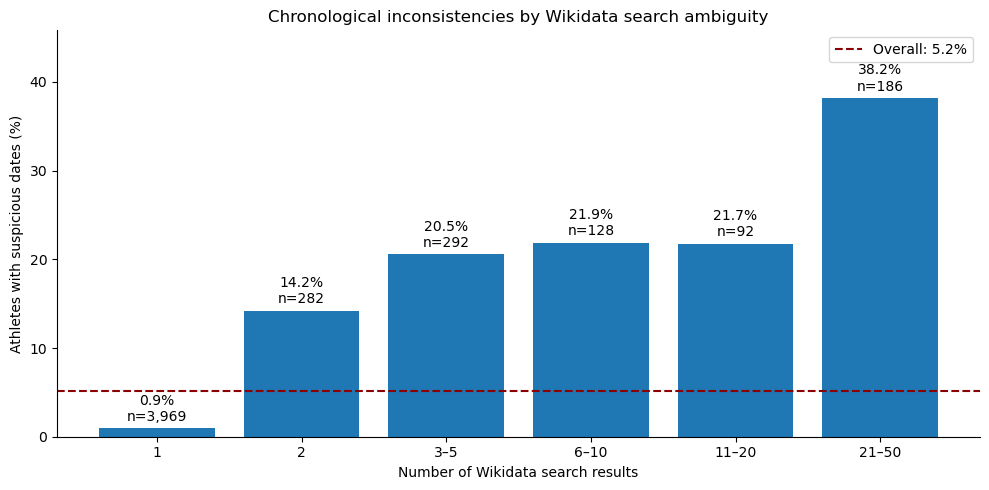

In [8]:
# Calculate the overall percentage of flagged athletes
total_percentage = (
    wikidata_result_quality["flagged"].sum()
    / wikidata_result_quality["athletes"].sum()
    * 100
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    wikidata_result_quality.index.astype(str),
    wikidata_result_quality["flagged_percentage"]
)

# Add the overall percentage as a reference line
ax.axhline(
    y=total_percentage,
    color="darkred",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall: {total_percentage:.1f}%"
)

# Add percentages and sample sizes above the bars
for bar, percentage, count in zip(
    bars,
    wikidata_result_quality["flagged_percentage"],
    wikidata_result_quality["athletes"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{percentage:.1f}%\nn={count:,}",
        ha="center",
        va="bottom"
    )

ax.set_title("Chronological inconsistencies by Wikidata search ambiguity")
ax.set_xlabel("Number of Wikidata search results")
ax.set_ylabel("Athletes with suspicious dates (%)")
ax.set_ylim(0, wikidata_result_quality["flagged_percentage"].max() * 1.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend()
plt.tight_layout()
plt.show()

#### Findings

I observed a strong association between the number of Wikidata search results and the frequency of chronological inconsistencies.

Among athletes for whom the Wikidata search returned exactly one result, only 0.9% were flagged as suspicious. This percentage increased to 14.2% for searches returning two results and reached 38.2% for searches returning between 21 and 50 results.

Overall, 22.5% of athletes with multiple search results were flagged, compared with 0.9% of athletes with a single result.

These findings suggest that selecting the first Wikidata search result becomes increasingly unreliable as the number of possible candidates increases. They support the development of a matching procedure that evaluates candidate identities rather than relying exclusively on search-result ranking.

**Limitations:** Chronological inconsistencies indicate potentially incorrect matches, not confirmed identification errors. Conversely, a chronologically plausible result is not necessarily the correct athlete. Athletes without a recorded Wikidata search-result count in the analyzed ranges were excluded from this comparison.

**Note:** This comparison includes 4,949 athletes with 1–50 Wikidata search results. There are 77 athletes without any search results who are excluded.

### 3.2 Biographical completeness across Olympic generations

The availability of biographical information is an important consideration when studying athletes' lifespans.

Athletes who participated in the early Olympic Games are likely to have died, whereas many recent Olympians are still alive. Consequently, the percentage of athletes with both a birthdate and a deathdate is expected to decrease for more recent Olympic generations. It is therefore important to distinguish between athletes who are reported as alive and those whose deathdate is missing for other reasons.

Missing information may also result from unsuccessful biographical matches or incomplete historical records, particularly for athletes from earlier Olympic generations.

To investigate these patterns, athletes are classified according to their available birthdates, deathdates, and reported living status. The distribution of these categories is then compared across Olympic decades.

An athlete who participated in multiple decades is counted once in each relevant decade.

In [9]:
lifespan_quality = athletes_df[["ID", "birthdate", "deathdate", "status"]].copy()

lifespan_quality["has_birthdate"] = (lifespan_quality["birthdate"].notna())

lifespan_quality["has_deathdate"] = (lifespan_quality["deathdate"].notna())

def classify_lifespan(row):
    if row["has_birthdate"] and row["has_deathdate"]:
        return "Deceased (dates known)"
    if row["status"] == "Alive":
        return "Alive"
    if row["has_birthdate"]:
        return "Birthdate only, status unknown"
    if row["has_deathdate"]:
        return "Deathdate only"
    return "No dates available"

lifespan_quality["lifespan_category"] = (lifespan_quality.apply(classify_lifespan, axis=1))

lifespan_quality["lifespan_category"].value_counts()

lifespan_category
Alive                             3046
Deceased (dates known)            1232
No dates available                1001
Birthdate only, status unknown     408
Deathdate only                       6
Name: count, dtype: int64

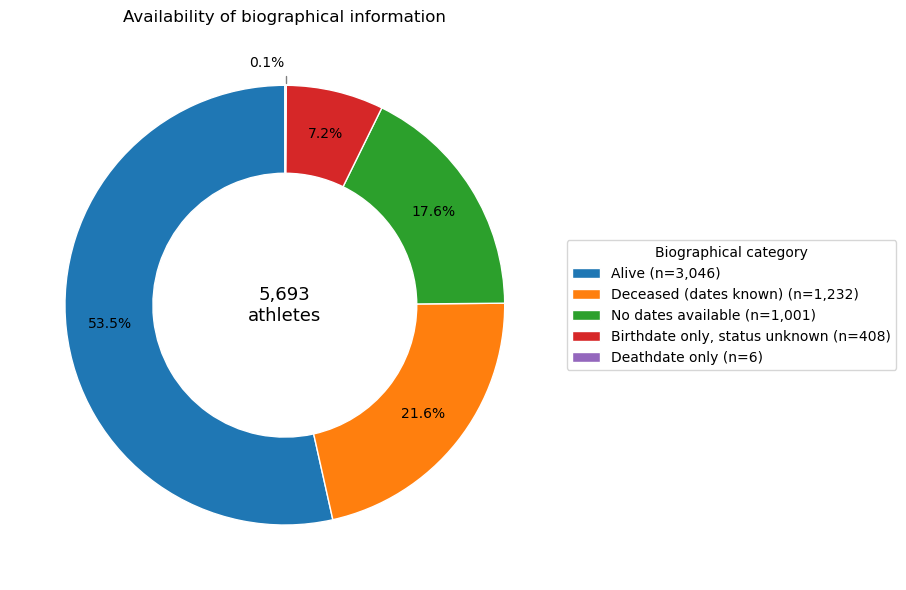

In [15]:
import numpy as np

# Count athletes in each lifespan category
category_counts = lifespan_quality["lifespan_category"].value_counts()

# Create the donut chart
fig, ax = plt.subplots(figsize=(9, 6))

wedges, _, autotexts = ax.pie(
    category_counts,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 2 else "",
    startangle=90,
    pctdistance=0.8,
    wedgeprops={"width": 0.4, "edgecolor": "white"}
)

# Add an external label with a leader line for the smallest category
smallest_category = "Deathdate only"
index = category_counts.index.get_loc(smallest_category)
wedge = wedges[index]

# Calculate the midpoint angle of the slice
angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
x, y = np.cos(angle), np.sin(angle)

# Place the label outside the donut and connect it to the slice
ax.annotate(
    f"{category_counts[smallest_category] / category_counts.sum() * 100:.1f}%",
    xy=(x, y),
    xytext=(0, 1.1),
    ha="right",
    va="center",
    arrowprops={
        "arrowstyle": "-",
        "color": "gray",
        "connectionstyle": "angle,angleA=0,angleB=90,rad=5"
    }
)

# Display the total number of athletes in the centre
ax.text(
    0, 0,
    f"{category_counts.sum():,}\nathletes",
    ha="center",
    va="center",
    fontsize=13
)

# Add a legend with category names and counts
ax.legend(
    wedges,
    [f"{category} (n={count:,})"
     for category, count in category_counts.items()],
    title="Biographical category",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.set_title("Availability of biographical information")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [17]:
# Select athlete IDs and Olympic participation years
decade_df = df[["ID", "Year"]].copy()

# Determine the decade of each Olympic participation
decade_df["decade"] = (decade_df["Year"] // 10 * 10)

# Count each athlete only once per decade
decade_df = decade_df.drop_duplicates(subset=["ID", "decade"])

# Add the lifespan category of each athlete
decade_df = decade_df.merge(
    lifespan_quality[["ID", "lifespan_category"]],
    on="ID",
    how="left"
)

# Count athletes in each lifespan category per decade
decade_counts = (
    decade_df.groupby(["decade", "lifespan_category"])
    .size()
    .unstack(fill_value=0)
)

# Calculate the percentage of athletes in each category per decade
decade_percentages = (
    decade_counts
    .div(decade_counts.sum(axis=1), axis=0)
    * 100
)

# Display the percentages with one decimal place
decade_percentages.style.format("{:.1f}%")

lifespan_category,Alive,"Birthdate only, status unknown",Deathdate only,Deceased (dates known),No dates available
decade,,,,,
1890,0.0%,37.5%,0.0%,50.0%,12.5%
1900,2.2%,4.4%,0.0%,67.6%,25.7%
1910,2.6%,6.9%,0.0%,76.7%,13.8%
1920,1.0%,6.3%,0.3%,73.2%,19.2%
1930,3.5%,9.1%,0.0%,70.7%,16.7%
1940,2.4%,9.1%,1.0%,61.1%,26.4%
1950,9.8%,12.4%,0.0%,62.4%,15.4%
1960,36.1%,6.6%,0.2%,38.0%,19.2%
1970,53.4%,6.9%,0.2%,21.8%,17.7%


Interestingly, some athletes who participated in the earliest Olympic decades are classified as alive. Given the time elapsed since their participation, these classifications are highly unlikely to be correct and may indicate incorrect biographical matches. This issue is examined further in Section 3.3.

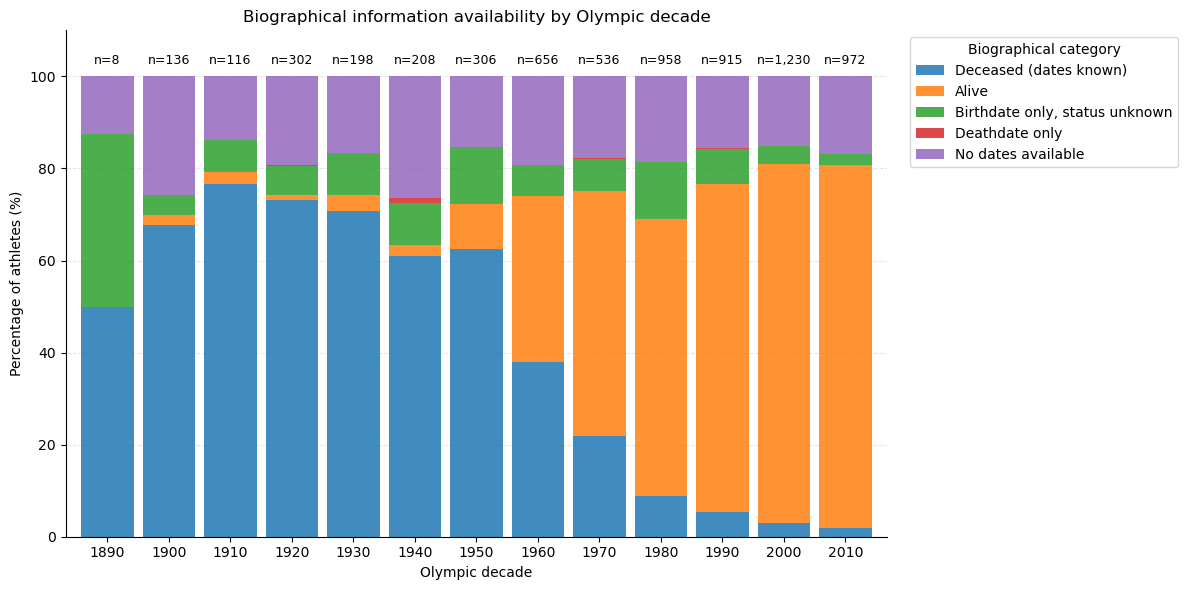

In [23]:
# Define the order of the biographical categories
category_order = [
    "Deceased (dates known)",
    "Alive",
    "Birthdate only, status unknown",
    "Deathdate only",
    "No dates available"
]

# Arrange categories in the desired stacking order
plot_data = decade_percentages.reindex(
    columns=category_order,
    fill_value=0
)

# Calculate the number of unique athletes per decade
decade_sizes = decade_counts.sum(axis=1).reindex(plot_data.index)

# Create a 100% stacked bar chart
ax = plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.85,
    alpha=0.85
)

# Add the title and axis labels
ax.set_title("Biographical information availability by Olympic decade")
ax.set_xlabel("Olympic decade")
ax.set_ylabel("Percentage of athletes (%)")
ax.set_ylim(0, 100)

# Leave space above the bars for sample sizes
ax.set_ylim(0, 110)

# Display the number of athletes above each bar
for i, decade in enumerate(plot_data.index):
    ax.text(
        i,
        102,
        f"n={decade_sizes.loc[decade]:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Display each decade with its corresponding sample size
ax.set_xticklabels(plot_data.index)
ax.tick_params(axis="x", rotation=0)

# Add subtle horizontal gridlines
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.set_yticks(range(0, 101, 20))

# Position the legend outside the chart
ax.legend(
    title="Biographical category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

#### Findings

The availability of complete lifespan information varies considerably across Olympic generations.

Among athletes who participated in the 1910s, 76.7% have both a recorded birthdate and deathdate. This proportion decreases to 38.0% in the 1960s, 8.8% in the 1980s, and just 2.0% in the 2010s.

Conversely, the proportion of athletes classified as alive increases from 2.6% in the 1910s to 78.8% in the 2010s. This is broadly consistent with the expected differences between historical and recent Olympic generations.

However, the data also contain anomalies. Some athletes who competed in the early twentieth century are classified as alive, suggesting possible errors in biographical identification or living-status information.

Missing biographical information remains an important limitation across generations. For example, 25.7% of athletes from the 1900s have neither a recorded birthdate nor a deathdate. Interestingly, this percentage does not appear to follow a clear trend across Olympic decades. Combining this category with athletes who have only a recorded birthdate and an unknown living status, we see a slight decrease over time. However, the pattern is not consistent enough to draw any firm conclusions.

These patterns have important implications for future lifespan research. An analysis restricted to athletes with known birthdates and deathdates would disproportionately exclude recent Olympic generations. Furthermore, the presence of apparently incorrect living-status information highlights the need for additional validation before applying survival analysis.

### 3.3 Chronological inconsistencies across Olympic generations

Historical biographical records may be incomplete or ambiguous, potentially making it more difficult to identify athletes who competed in earlier Olympic Games.

To investigate whether chronological inconsistencies vary across generations, the percentage of athletes flagged by at least one quality check is calculated for each Olympic decade.

As in the previous analysis, athletes are counted once per decade, even if they participated in multiple Olympic Games during that period.

In [28]:
# Create a working copy of the quality assessment data
decade_quality = quality_df.copy()

# Determine the decade of each Olympic participation
decade_quality["decade"] = (
    decade_quality["Year"] // 10 * 10
)

# Flag an athlete within a decade if any participation is flagged
decade_quality = (
    decade_quality
    .groupby(["ID", "decade"], as_index=False)
    .agg(flagged=("flagged", "any"))
)

# Calculate the number and percentage of flagged athletes per decade
decade_quality_summary = (
    decade_quality.groupby("decade")
    .agg(
        athletes=("ID", "count"),
        flagged=("flagged", "sum"),
        flagged_percentage=("flagged", "mean")
    )
)

# Convert proportions to percentages
decade_quality_summary["flagged_percentage"] *= 100

# Create a working copy with the individual quality checks
decade_flag_quality = quality_df[["ID", "Year"] + flag_columns].copy()

# Determine the decade of each participation
decade_flag_quality["decade"] = (
    decade_flag_quality["Year"] // 10 * 10
)

# Count each athlete once per decade for each quality check
decade_flag_quality = (
    decade_flag_quality
    .groupby(["ID", "decade"], as_index=False)[flag_columns]
    .any()
)

# Calculate the percentage of athletes flagged by each check
decade_flag_summary = (
    decade_flag_quality
    .groupby("decade")[flag_columns]
    .mean() * 100
)

decade_flag_summary.round(1)

# Display the results rounded to one decimal place
decade_quality_summary.round(1)

,athletes,flagged,flagged_percentage
decade,,,
1890,8,4,50.0
1900,136,21,15.4
1910,116,10,8.6
1920,302,17,5.6
1930,198,20,10.1
1940,208,19,9.1
1950,306,21,6.9
1960,656,38,5.8
1970,536,25,4.7


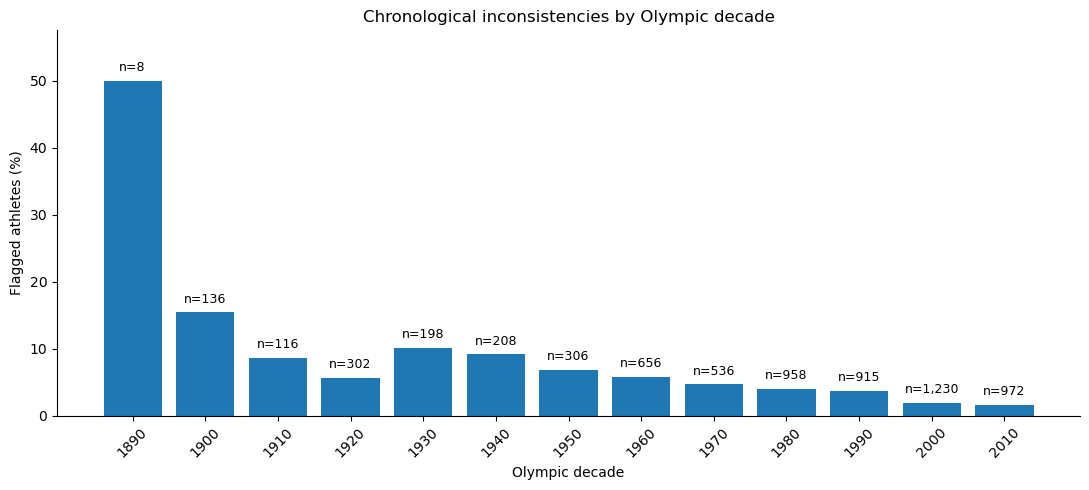

In [25]:
# Create a bar chart showing the percentage of flagged athletes per decade
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    decade_quality_summary.index.astype(str),
    decade_quality_summary["flagged_percentage"]
)

# Add the sample size above each bar
for bar, n in zip(bars, decade_quality_summary["athletes"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"n={n:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Add the title and axis labels
ax.set_title("Chronological inconsistencies by Olympic decade")
ax.set_xlabel("Olympic decade")
ax.set_ylabel("Flagged athletes (%)")

# Leave room for the sample size labels
ax.set_ylim(0, decade_quality_summary["flagged_percentage"].max() * 1.15)

# Rotate decade labels for readability
ax.tick_params(axis="x", rotation=45)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

#### Findings

The frequency of detected chronological inconsistencies generally decreases across Olympic generations.

Among athletes who competed in the 1900s, 15.4% were flagged. This percentage decreases to 10.1% in the 1930s, 5.8% in the 1960s, 4.0% in the 1980s, and 1.6% in the 2010s.

The earliest decade in the dataset, the 1890s, has a particularly high percentage of flagged athletes (50.0%). However, this represents only four athletes out of eight, making the percentage highly sensitive to individual observations.

The results suggest that chronological inconsistencies are more frequently detected among historical Olympic athletes. However, this does not necessarily mean that older records have a higher true identification-error rate.

Historical athletes are more likely to have recorded deathdates, providing additional opportunities to detect inconsistencies. Conversely, missing dates and the fact that many recent Olympians are still alive can make incorrect matches involving recent athletes harder to identify.

The observed differences should therefore be interpreted as differences in detectable chronological inconsistencies rather than direct estimates of matching accuracy.

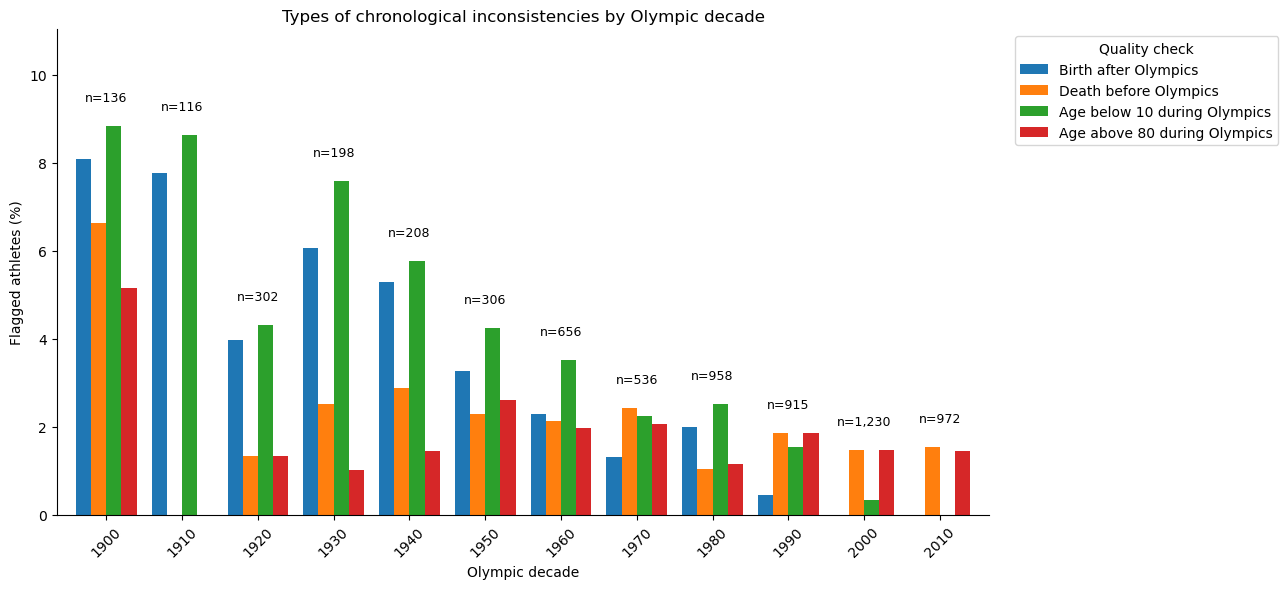

In [31]:
# Use descriptive labels for the four quality checks
flag_labels = {
    "birth_after_olympics": "Birth after Olympics",
    "death_before_olympics": "Death before Olympics",
    "age_below_10": "Age below 10 during Olympics",
    "age_above_80": "Age above 80 during Olympics"
}

# Exclude the 1890s due to the small sample size
plot_data = decade_flag_summary.loc[1900:].rename(columns=flag_labels)

# Get the number of athletes in each decade
decade_sizes = decade_quality_summary.loc[plot_data.index, "athletes"]

# Create a grouped bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

# Leave space above the bars for sample sizes
ax.set_ylim(0, plot_data.max().max() * 1.25)

# Add sample sizes above each group of bars
for i, (decade, n) in enumerate(decade_sizes.items()):
    ax.text(
        i,
        plot_data.loc[decade].max() + 0.5,
        f"n={n:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Add title and axis labels
ax.set_title("Types of chronological inconsistencies by Olympic decade")
ax.set_xlabel("Olympic decade")
ax.set_ylabel("Flagged athletes (%)")

ax.tick_params(axis="x", rotation=45)

ax.legend(
    title="Quality check",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

#### Findings by type of chronological inconsistency

The frequency of the four types of chronological inconsistencies varies across Olympic decades.

Birthdates recorded after Olympic participation and deathdates recorded before Olympic participation account for many of the detected inconsistencies. Implausible ages, either below 10 or above 80 during Olympic participation, are generally less common.

The percentage of athletes with birthdates recorded after their Olympic participation appears to decrease across generations. In contrast, inconsistencies involving deathdates remain present in more recent decades, even as the overall percentage of flagged athletes decreases.

These patterns suggest that the different types of chronological inconsistencies do not necessarily follow the same trend over time.

However, the percentages should be interpreted with caution, particularly for earlier decades with relatively small sample sizes. The 1890s are excluded from this graph because only eight athletes are represented in that decade.

In [36]:
# Create a working copy with the individual quality checks
decade_flag_quality = quality_df[["ID", "Year"] + flag_columns].copy()

# Determine the decade of each participation
decade_flag_quality["decade"] = (
    decade_flag_quality["Year"] // 10 * 10
)

# Combine all participations within each decade
decade_flag_quality = (
    decade_flag_quality
    .groupby(["ID", "decade"], as_index=False)[flag_columns]
    .any()
)

# Assign each athlete to at most one category per decade
# Priority follows the order in flag_columns
for i, col in enumerate(flag_columns):
    if i > 0:
        decade_flag_quality[col] &= ~decade_flag_quality[
            flag_columns[:i]
        ].any(axis=1)

# Keep only flagged athletes
flagged_decade_quality = decade_flag_quality[
    decade_flag_quality[flag_columns].any(axis=1)
].copy()

# Calculate the percentage of flagged athletes in each category
decade_flag_composition = (
    flagged_decade_quality
    .groupby("decade")[flag_columns]
    .mean() * 100
)

# Count flagged athletes per decade
flagged_decade_sizes = (
    flagged_decade_quality.groupby("decade").size()
)

decade_flag_composition.style.format("{:.1f}%")

,birth_after_olympics,death_before_olympics,age_below_10,age_above_80
decade,,,,
1890,75.0%,0.0%,0.0%,25.0%
1900,52.4%,42.9%,4.8%,0.0%
1910,90.0%,0.0%,10.0%,0.0%
1920,70.6%,23.5%,5.9%,0.0%
1930,60.0%,25.0%,15.0%,0.0%
1940,57.9%,31.6%,5.3%,5.3%
1950,47.6%,33.3%,14.3%,4.8%
1960,39.5%,36.8%,21.1%,2.6%
1970,28.0%,52.0%,20.0%,0.0%


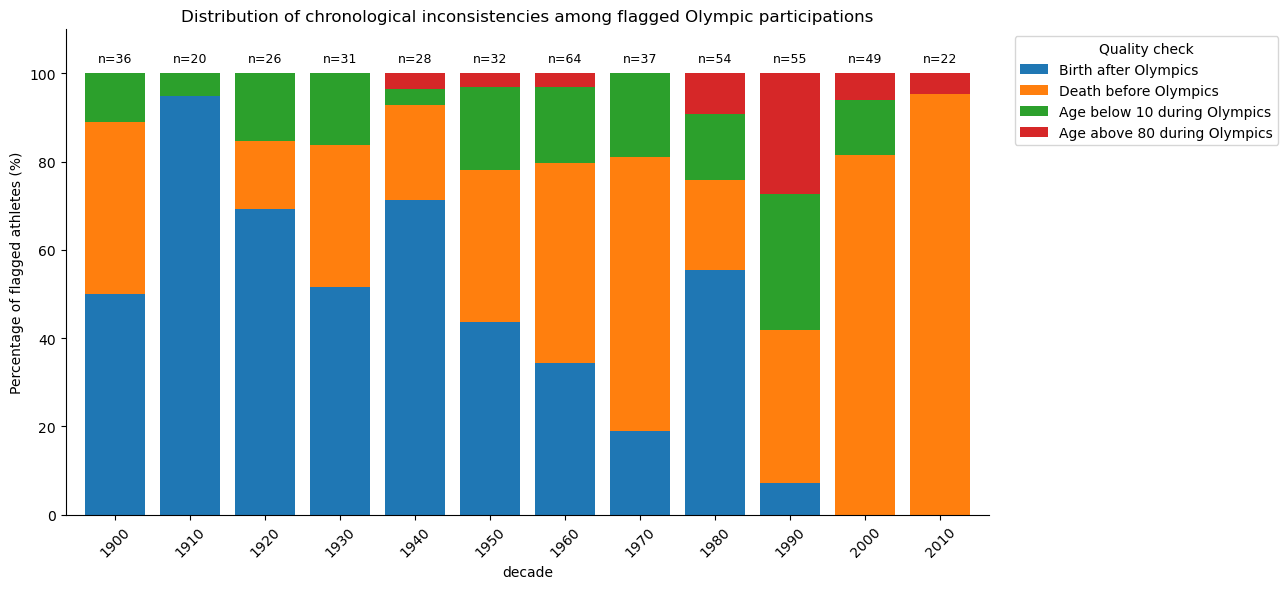

In [39]:
# Prepare the data
plot_data = (
    decade_flag_composition
    .loc[1900:]
    .rename(columns=flag_labels)
)

decade_sizes = flagged_decade_sizes.loc[plot_data.index]

# Create a stacked bar chart
ax = plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    width=0.8
)

# Leave space for sample sizes
ax.set_ylim(0, 110)

# Add sample sizes
for i, (decade, n) in enumerate(decade_sizes.items()):
    ax.text(
        i,
        102,
        f"n={n:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title("Distribution of chronological inconsistencies among flagged Olympic participations")
ax.set_ylabel("Percentage of flagged participations (%)")    
ax.set_ylabel("Percentage of flagged athletes (%)")

ax.tick_params(axis="x", rotation=45)

ax.legend(
    title="Quality check",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

#### Findings: Distribution of inconsistency types

The relative distribution of chronological inconsistencies changes considerably across Olympic generations.

Among flagged athletes from earlier Olympic decades, birthdates recorded after Olympic participation account for a substantial proportion of inconsistencies. This category becomes less common in later decades and is absent among flagged athletes from the 2000s and 2010s.

Conversely, deathdates recorded before Olympic participation become increasingly prominent in more recent decades. In the 2000s and 2010s, they account for the majority of flagged athletes. Implausible ages during Olympic participation generally account for smaller proportions, although their relative importance varies between decades.

One possible explanation is that incorrect biographical matches involve different types of people across generations. Historical athletes may be incorrectly matched to people born later, while more recent athletes may be matched to historical individuals who died before the Olympic participation took place. However, this hypothesis would require further investigation of individual matches.

The results should also be interpreted with caution because the number of flagged athletes per decade is relatively small. Additionally, athletes with multiple inconsistency types within the same decade are assigned to a single category using a fixed priority order.

Overall, the findings suggest that not only the frequency but also the types of detectable chronological inconsistencies vary across Olympic generations.

In [40]:
# Select flagged participations
flagged_records = quality_df[quality_df["flagged"]].copy()

# Determine Olympic decade
flagged_records["decade"] = flagged_records["Year"] // 10 * 10

# Count flagged participations per athlete per decade
participation_counts = (
    flagged_records
    .groupby(["ID", "decade"])
    .size()
)

# Identify athletes with multiple flagged participations in a decade
multiple_participations = participation_counts[
    participation_counts > 1
]

print(f"Athletes affected: {multiple_participations.index.get_level_values('ID').nunique()}")
print(f"Athlete-decade combinations affected: {len(multiple_participations)}")
print(f"Extra flagged records: {(multiple_participations - 1).sum()}")

# Identify the inconsistency category for each flagged participation
flagged_records["flag_category"] = (
    flagged_records[flag_columns].idxmax(axis=1)
)

# Count distinct categories per athlete per decade
category_counts = (
    flagged_records
    .groupby(["ID", "decade"])["flag_category"]
    .nunique()
)

# Identify athletes with different inconsistency types within a decade
different_categories = category_counts[category_counts > 1]

print(f"Athletes with different categories: {different_categories.index.get_level_values('ID').nunique()}")
print(f"Athlete-decade combinations with different categories: {len(different_categories)}")

Athletes affected: 84
Athlete-decade combinations affected: 93
Extra flagged records: 172


#### Checking the effect of multiple Olympic participations

Some athletes participated in multiple Olympic Games within the same decade. Counting each participation separately would give these athletes more weight in the analysis.

To investigate the potential impact, the number of athletes with multiple flagged participation records was calculated. In total, 84 athletes had multiple flagged records within at least one decade, resulting in 172 additional records compared with counting each athlete once per decade.

Only two athletes had different types of chronological inconsistencies within the same decade.

To maintain consistency with the previous analyses and avoid giving additional weight to athletes with multiple participations, each athlete is counted once per decade. Where multiple inconsistency types occur, a fixed priority order is used to assign a single category.

#### Findings

The frequency of detected chronological inconsistencies generally decreases across Olympic generations.

Among athletes who competed in the 1900s, 15.4% were flagged as suspicious. This percentage decreases to 10.6% in the 1930s, 5.8% in the 1960s, 4.1% in the 1980s, and 1.6% in the 2010s.

The earliest decade in the dataset, the 1890s, has a particularly high suspicious-record rate of 50.0%. However, this represents only four athletes out of eight, making the percentage highly sensitive to individual observations.

The results suggest that chronological inconsistencies are more frequently detected among historical Olympic athletes. However, this does not necessarily mean that older records have a higher true identification-error rate.

Historical athletes are more likely to have recorded deathdates, providing additional opportunities to detect inconsistencies. Conversely, missing dates and the shorter elapsed time since participation can make incorrect matches involving recent athletes harder to identify.

The observed differences should therefore be interpreted as differences in detectable chronological inconsistencies rather than direct estimates of matching accuracy.

## 4. Limitations

Several limitations should be considered when interpreting these findings.

### 4.1 Preliminary sample

The analysis uses 5,693 athletes from the first 21 completed scraping batches rather than the full Olympic dataset. Depending on the order in which athletes were processed, this sample may not be representative of all Olympic participants.

Consequently, the reported percentages should be interpreted as descriptive statistics for the analyzed sample.

### 4.2 Chronological plausibility does not guarantee correct identification

The quality checks identify implausible combinations of birthdates, deathdates, and Olympic participation years.

However, an incorrect Wikidata match may still have plausible dates. The reported percentages therefore represent the frequency of detected chronological inconsistencies, not the true rate of incorrect identity matches.

Similarly, a suspicious record does not necessarily prove that the selected identity is incorrect. Errors in the underlying source data may also produce inconsistencies.

### 4.3 Missing information

Missing birthdates and deathdates limit the effectiveness of chronological validation.

Athletes without sufficient biographical information may pass the quality checks simply because an inconsistency cannot be evaluated.

Furthermore, a missing deathdate does not necessarily indicate that an athlete is alive.

### 4.4 Search-result counts

The number of Wikidata search results depends on the search terms and name variations used by the scraper. Searches are also limited to a maximum number of returned results.

The result count should therefore be interpreted as an indicator of search ambiguity, rather than a complete count of all possible identities.

### 4.5 Differences between Olympic generations

The ability to detect chronological inconsistencies varies across historical periods. Older athletes are more likely to have recorded deathdates, while many recent athletes are still alive.

As a result, differences in suspicious-match percentages between decades may partly reflect differences in data completeness rather than actual matching accuracy.

## 5. Conclusions and Next Steps

This exploratory analysis examined the reliability and completeness of biographical information collected for Olympic athletes.

Three main findings emerged:

1. **Wikidata search ambiguity is strongly associated with chronological inconsistencies.** Athletes with multiple possible Wikidata matches were substantially more likely to have suspicious biographical information than athletes with a single search result.

2. **Biographical completeness varies across Olympic generations.** The availability of complete lifespans decreases for more recent athletes, emphasizing the importance of accounting for living individuals in subsequent longevity research.

3. **Detected chronological inconsistencies vary across historical periods.** Earlier Olympic generations generally show higher rates of suspicious records, although differences in data completeness and sample sizes complicate interpretation.

### Next steps

The most immediate priority is to improve the Wikidata matching procedure.

Rather than automatically selecting the first search result, future versions of the scraper will evaluate candidate identities using additional information, such as names, birthdates, and Olympic participation years.

The improved approach will be tested against the existing scraper before being applied to the complete dataset.

Once reliable biographical information has been collected, the project will proceed to its primary research question: investigating the lifespans of Olympic athletes.

Depending on the completeness of the final dataset, survival analysis may be used to account for athletes who are still alive.

The current findings provide a foundation for improving the data collection process and establishing the limitations of the subsequent lifespan analysis.